### 1(a) Implementation of Linear Regression, Ridge and Lasso Regression

**Aim:** To implement Linear Regression and apply Ridge and Lasso regularization methods to analyze their performance.

**Theory:**
- **Linear Regression:** Predicts a continuous target variable by establishing a linear relationship between input features and the target.
- **Ridge Regression:** Uses L2 regularization to reduce the effect of large model coefficients and help prevent overfitting.
- **Lasso Regression:** Uses L1 regularization and can reduce some feature coefficients to zero, performing feature selection.

**Evaluation Metrics:** Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R² score.

**Dataset:** Diabetes dataset available in Scikit-learn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
data = load_diabetes()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=10000))
}

results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mean_squared_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

regression_results = pd.DataFrame(results)
display(regression_results.round(3))

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,42.794,2900.194,53.853,0.453
1,Ridge,42.812,2892.015,53.777,0.454
2,Lasso,42.805,2884.624,53.709,0.456


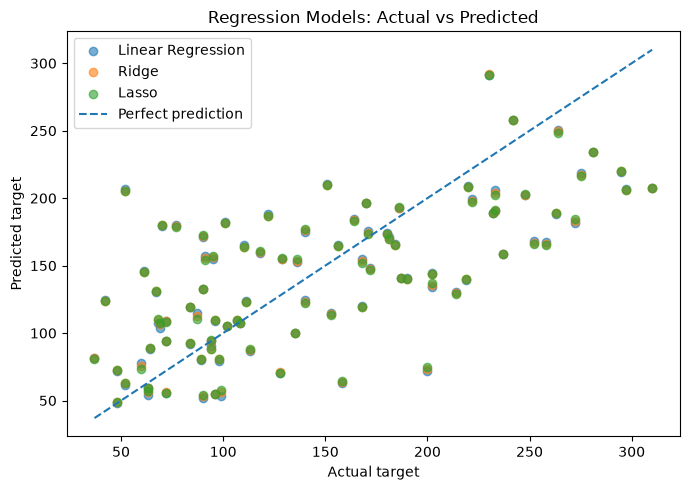

In [3]:
# Graph: actual versus predicted target values
plt.figure(figsize=(7, 5))
for name, pred in predictions.items():
    plt.scatter(y_test, pred, alpha=0.6, label=name)
low = min(y_test.min(), min(p.min() for p in predictions.values()))
high = max(y_test.max(), max(p.max() for p in predictions.values()))
plt.plot([low, high], [low, high], linestyle="--", label="Perfect prediction")
plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.title("Regression Models: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

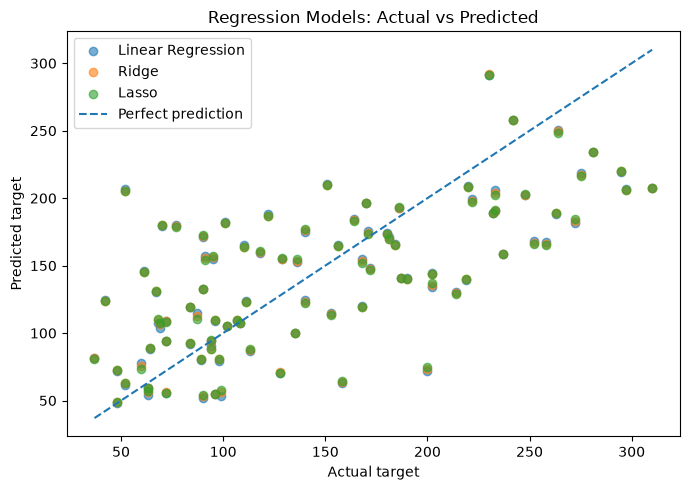

In [4]:
# Graph: actual versus predicted target values
plt.figure(figsize=(7, 5))
for name, pred in predictions.items():
    plt.scatter(y_test, pred, alpha=0.6, label=name)
low = min(y_test.min(), min(p.min() for p in predictions.values()))
high = max(y_test.max(), max(p.max() for p in predictions.values()))
plt.plot([low, high], [low, high], linestyle="--", label="Perfect prediction")
plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.title("Regression Models: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

**Result and Conclusion:**

Linear Regression, Ridge Regression, and Lasso Regression were implemented and evaluated using the diabetes dataset. Their performance was compared using MAE, MSE, RMSE, and R² score.

The model with lower prediction errors and a higher R² score generally provides better predictions. Ridge and Lasso regularization help control model complexity and can reduce overfitting.